# hvo5 validation evidence

Recomputes the monthly series, the longest zero-commit run, and a first-pass theme label for each of kbissonn's ten projects, from `partner_data/kbissonn_project_summary.csv`.

The reviewed judgments are in `build_outputs.py` and `hvo5_validation_log.csv`. Two places the first-pass flag is not the final label: mapxmaps has one commit after a 63-month gap, but that commit is an executive-order content edit, so HasRecovered stays No. Keyword themes are only a hint. RecentThemes in the log was read off the last 10 commit messages.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import analyze_evidence as ae
import build_outputs as bo

summary = ae.load_summary('partner_data/kbissonn_project_summary.csv')
results = {project: ae.analyze_project(group) for project, group in summary.groupby('project')}

rows = []
for i, project in enumerate(bo.PROJECTS):
    r = results[project]
    rows.append({
        'project': project,
        'commits': r['ncommits'],
        'from': r['from'],
        'to': r['to'],
        'longest_gap': f"{r['longest_start']} to {r['longest_end']} ({r['longest_len']} mo)",
        'gaps_of_3mo': r['n_gaps_3'],
        'commits_after_gap': r['commits_after'],
        'first_pass_recovered': r['has_recovered'],
        'author_recovered': bo.AUTHOR['HasRecovered'][i],
        'validator_recovered': bo.VALIDATOR['HasRecovered'][i],
        'first_pass_pattern': r['pattern'],
        'author_pattern': bo.AUTHOR['ActivityPattern'][i],
        'validator_pattern': bo.VALIDATOR['ActivityPattern'][i],
        'status': r['current'],
        'author_status': bo.AUTHOR['Currentstatus'][i],
    })
comparison = pd.DataFrame(rows)
comparison


,project,commits,from,to,longest_gap,gaps_of_3mo,commits_after_gap,first_pass_recovered,author_recovered,validator_recovered,first_pass_pattern,author_pattern,validator_pattern,status,author_status
0,juliagaussianprocesses_abstractgps.jl,1702,2020-04-18,2026-03-20,2026-02 to 2026-02 (1 mo),0,34,No,Yes,No,declining,Declining,Declining,Active,Active
1,pyushkevich_itksnap,2597,2006-12-02,2025-10-27,2010-11 to 2011-03 (5 mo),7,2201,Yes,Yes,Yes,irregular,Irregular,Irregular,Active,Active
2,darrencroton_sage,624,2012-02-29,2025-11-04,2021-11 to 2024-02 (28 mo),11,173,Yes,Yes,Yes,irregular,Irregular,Irregular,Active,Inactive
3,nanograv_enterprise,2012,2017-01-17,2025-10-22,2025-05 to 2025-07 (3 mo),1,18,Yes,Yes,Yes,irregular,Cyclical,Irregular,Active,Active
4,nsidc_mapxmaps,244,1992-12-30,2025-01-22,2019-10 to 2024-12 (63 mo),22,1,Yes,No,No,irregular,Irregular,Irregular,Inactive,Inactive
5,kinnala_scikit-fem,4134,2017-12-25,2026-04-18,2026-02 to 2026-03 (2 mo),0,12,No,Yes,No,declining,Declining,Declining,Active,Active
6,alibaba_graphscope,18627,2020-07-30,2026-04-21,2020-08 to 2020-09 (2 mo),0,18626,No,Yes,No,steady,Declining,Declining,Active,Active
7,turinglang_bijectors.jl,2254,2018-09-13,2025-10-27,2019-05 to 2019-06 (2 mo),0,2204,No,Yes,No,irregular,Cyclical,Irregular,Active,Active
8,sandialabs_pecos,544,2016-01-26,2025-04-03,2022-05 to 2023-07 (15 mo),8,63,Yes,Yes,Yes,declining,Declining,Declining,Active,Active
9,sicara_tuto-fsl,174,2021-02-01,2022-06-02,2021-07 to 2021-10 (4 mo),2,68,Yes,No,Yes,U-shaped,Seasonal,Irregular,Inactive,Inactive


## Monthly commits

The shaded band is the longest run of months with zero commits. A run shorter than 3 months is not an inactivity gap under the assignment.

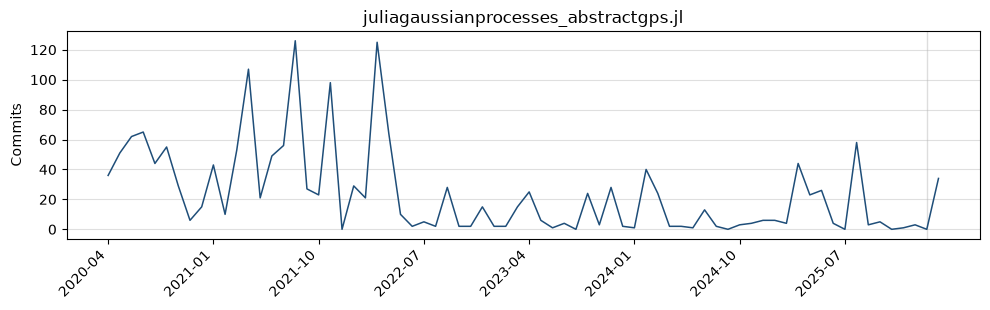

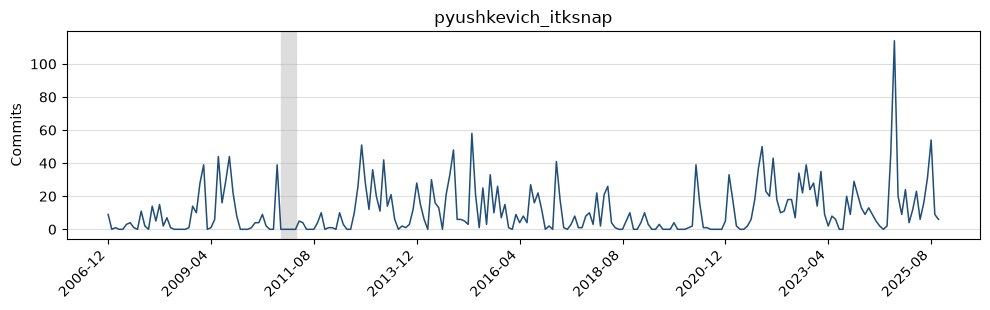

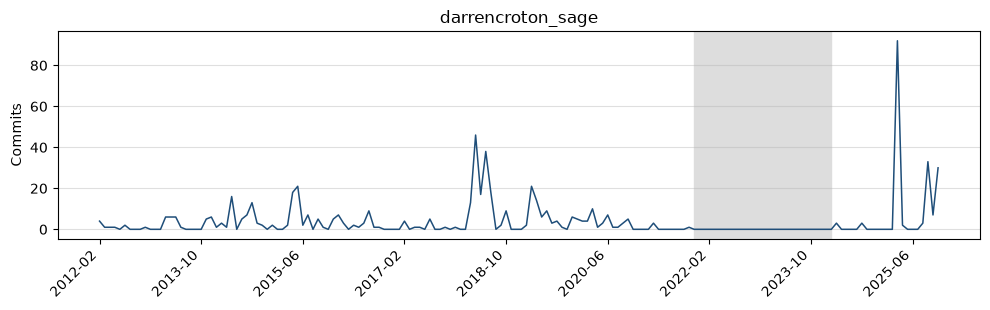

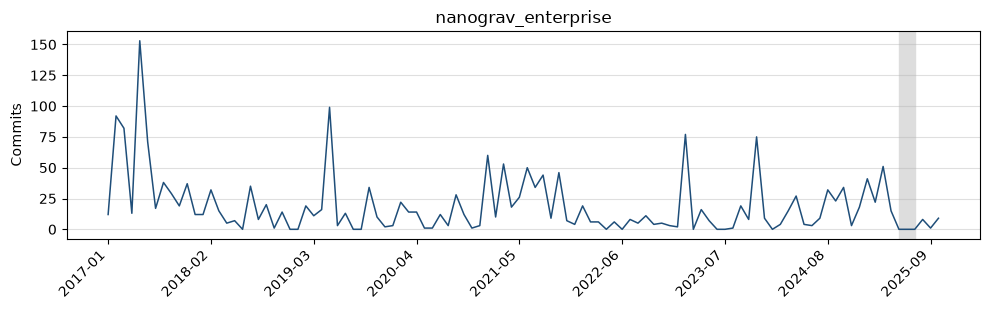

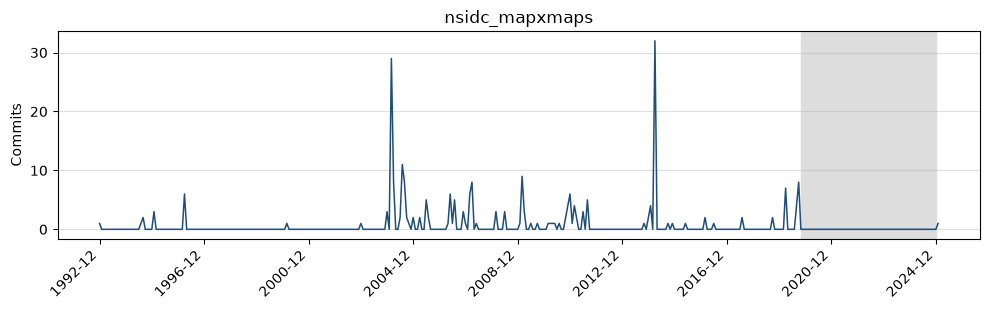

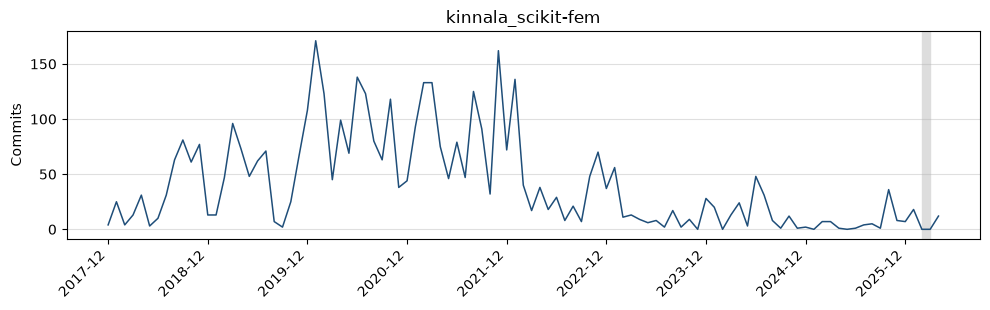

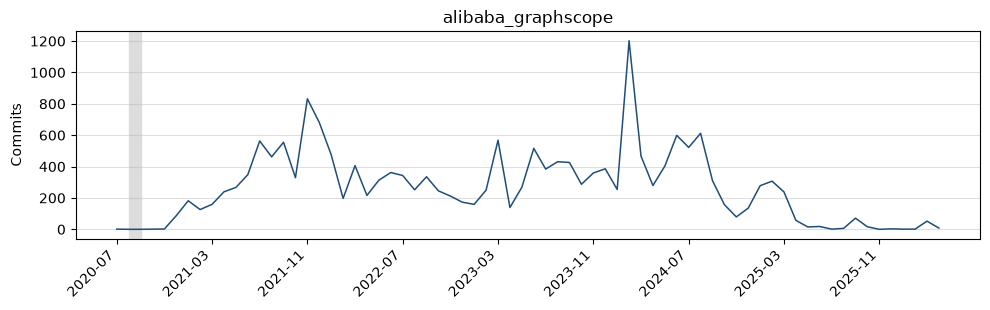

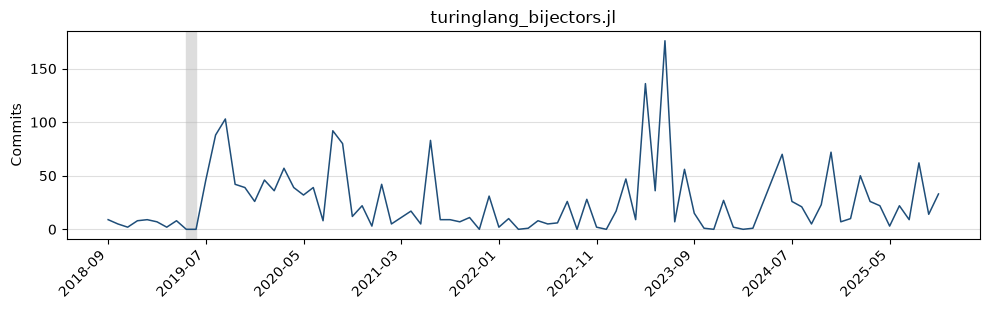

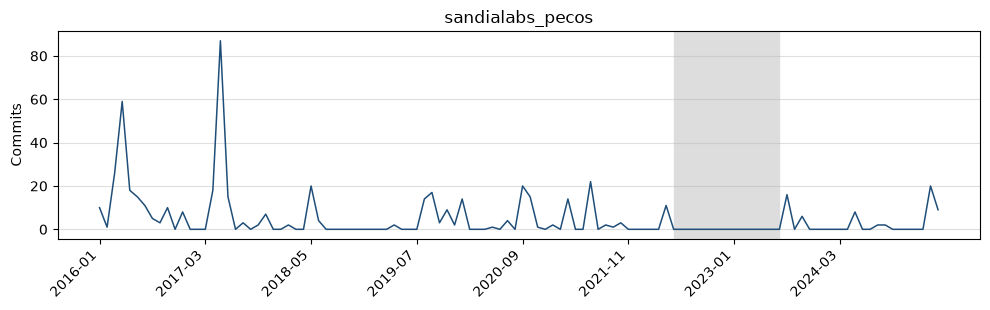

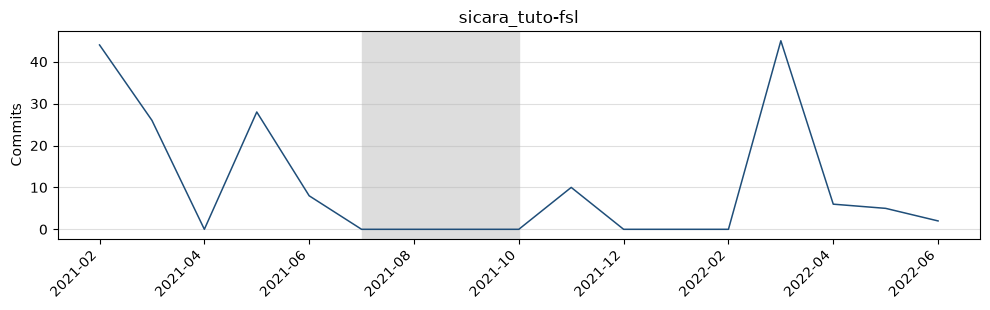

In [2]:
for project in bo.PROJECTS:
    r = results[project]
    series = r['series']
    labels = list(series.index)
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.plot(range(len(series)), series.to_numpy(), color='#1f4e79', lw=1.1)
    if r['longest_len']:
        ax.axvspan(labels.index(r['longest_start']), labels.index(r['longest_end']), color='#dddddd')
    step = max(len(labels) // 8, 1)
    ticks = list(range(0, len(labels), step))
    ax.set_xticks(ticks)
    ax.set_xticklabels([labels[i] for i in ticks], rotation=45, ha='right')
    ax.set_title(project)
    ax.set_ylabel('Commits')
    ax.grid(True, axis='y', alpha=0.4)
    fig.tight_layout()
    plt.show()


## Commits around the longest gap, and the latest commits

These snippets are what the RecentThemes, WhyRecovered, and HasRecovered rows are based on.

In [3]:
for project in bo.PROJECTS:
    r = results[project]
    print('=' * 88)
    print(project)
    print('BEFORE:', r['before_snip'])
    print('AFTER:', r['after_snip'])
    print('RECENT:', r['recent_snip'])
    print('keyword recent themes:', r['recent_themes'])


juliagaussianprocesses_abstractgps.jl
BEFORE: CompatHelper: bump compat for Optim to 2 for package 3-parametric-heteroscedastic, (keep existing compat) | CompatHelper: bump compat for Optim to 2 for package 1-mauna-loa, (keep existing compat) | CompatHelper: bump compat for Optim to 2 for package 0-intro-1d, (keep existing compat) | CompatHelper: bump compat for Turing to 0.42 for package ppl, (keep existing compat) | Added navbar and removed insert_navbar.sh | build based on c8b5872 | Merge e35cdc523bd083b7fced22e6f9e81e41057a8833 into 23dfd7a3e79f707e5812e0da873f3ec8b3f84d3d | CompatHelper: bump compat for Turing to 0.41 for package ppl, (keep existing compat)
AFTER: CompatHelper: bump compat for Turing to 0.43 for package ppl, (keep existing compat) | Use Turing Actions for JuliaGP docs and Navbar | Use Turing Actions for JuliaGP docs and Navbar (#446) | delete history | build based on 0083bfc | Update navbar (automated) | remove deploy docs from docs/make.jl | remove deploy docs fr

In [4]:
bo.main()
print('Wrote hvo5_validation_log.csv, hvo5_disagreement_resolution.csv, and hvo5_agreement_stats.csv')


rows 50 disagreements 22 {'HasRecovered': 5, 'WhyRecovered': 6, 'ActivityPattern': 3, 'Currentstatus': 1, 'RecentThemes': 7}
Wrote hvo5_validation_log.csv, hvo5_disagreement_resolution.csv, and hvo5_agreement_stats.csv
